In [9]:
!pip install pandas numpy scipy scikit-learn skorch matplotlib seaborn
!pip3 install torch --index-url https://download.pytorch.org/whl/cu128


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Looking in indexes: https://download.pytorch.org/whl/cu128

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip


In [10]:
import pandas as pd
import numpy as np
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.metrics import (
    root_mean_squared_error, mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, 
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, TensorDataset, DataLoader
import itertools

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from datetime import datetime

In [11]:
orig_df = pd.read_csv('full_weather.csv', parse_dates=['datetime'])


def get_state_datapoint_counts(df):
    """
    Return a DataFrame of states and their respective number of datetime records,
    sorted from most to least.
    """
    counts = (
        df.groupby('state')['datetime']
          .count()
          .reset_index(name='datapoint_count')
          .sort_values(by='datapoint_count', ascending=False)
    )
    return counts

# Example usage:
state_counts = get_state_datapoint_counts(orig_df)
print(state_counts)

def get_city_datapoint_counts(df):
    """
    Return a DataFrame of states and their respective number of datetime records,
    sorted from most to least.
    """
    counts = (
        df.groupby('city')['datetime']
          .count()
          .reset_index(name='datapoint_count')
          .sort_values(by='datapoint_count', ascending=False)
    )
    return counts

# Example usage:
state_counts = get_city_datapoint_counts(orig_df)
print(state_counts)

def get_place_datapoint_counts(df):
    """
    Return a DataFrame of states and their respective number of datetime records,
    sorted from most to least.
    """
    counts = (
        df.groupby('place')['datetime']
          .count()
          .reset_index(name='datapoint_count')
          .sort_values(by='datapoint_count', ascending=False)
    )
    return counts

# Example usage:
state_counts = get_place_datapoint_counts(orig_df)
print(state_counts)

def plot_state_month_heatmap(df, agg_col='temperature', agg_func='mean', scale=None):
    # Ensure month column exists
    if 'month' not in df.columns:
        df['month'] = df['datetime'].dt.month
    
    # Create pivot table: state vs month
    pivot_df = df.pivot_table(
        values=agg_col,
        index='state',
        columns='month',
        aggfunc=agg_func
    )
    
    scale_factor = 1
    scale_label = ""
    if scale == 'k':
        scale_factor = 1e3
        scale_label = " (k)"
    elif scale == 'M':
        scale_factor = 1e6
        scale_label = " (M)"
    
    pivot_df = pivot_df / scale_factor

    # Plot heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(pivot_df, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title(f"Heatmap of {agg_func} {agg_col}{scale_label} by State and Month", fontsize=14)
    plt.xlabel("Month")
    plt.ylabel("State")
    plt.show()

plot_state_month_heatmap(df_filtered, agg_col='temperature', agg_func='mean')
plot_state_month_heatmap(df_filtered, agg_col='precipitation_total', agg_func='mean')


In [12]:
def filter_top_place_per_state(df, state_col='state', place_col='place', datetime_col='datetime'):
    """
    Keep only the place with the highest datetime count for each state.

    Parameters:
    df (DataFrame): Input dataframe.
    state_col (str): Column name for state.
    place_col (str): Column name for place.
    datetime_col (str): Column name for datetime.

    Returns:
    DataFrame: Filtered dataframe.
    """
    # Count unique datetime values per state-place
    counts = (
        df.groupby([state_col, place_col])[datetime_col]
        .nunique()
        .reset_index(name='datetime_count')
    )

    # Get the place with the max datetime_count per state
    top_places = counts.loc[counts.groupby(state_col)['datetime_count'].idxmax()]

    # Merge back to original df
    return df.merge(top_places[[state_col, place_col]], on=[state_col, place_col])

df_filtered = filter_top_place_per_state(orig_df, state_col='state', place_col='place', datetime_col='datetime')

## Pre-processing datasets

In [13]:

pre_df = df_filtered


### Seasonal Interpolation of Missing Values
# Fill missing values per feature using monthly means.
pre_df['month'] = pre_df['datetime'].dt.month
features = [
    'temperature','pressure','dew_point','humidity','wind_speed',
    'gust','wind_chill','uv_index','feels_like_temperature',
    'visibility','solar_radiation','pollutant_value',
    'precipitation_rate','precipitation_total'
]

month_means = pre_df.groupby('month')[features].mean()

# Fill NaNs by mapping month to mean values
for feat in features:
    na_mask = pre_df[feat].isna()
    pre_df.loc[na_mask, feat] = pre_df.loc[na_mask, 'month'].map(month_means[feat])

### Outlier Removal (Z‑score ±3)
# z_scores = df[features].apply(zscore)
# mask = (np.abs(z_scores) <= 3).all(axis=1)
# print(f"Removing {len(df) - mask.sum()} outliers.")
# df = df[mask].reset_index(drop=True)


### Feature Engineering
# - 7-day rolling average of precipitation
# - Monsoon month flag (Nov–Mar)
# - Coastal state flag

# 7‑day rolling avg per place
pre_df = pre_df.sort_values(['place','datetime'])
pre_df['rainfall_7d_avg'] = pre_df.groupby('place')['precipitation_total'] \
    .transform(lambda x: x.rolling(7, min_periods=1).mean())

# Monsoon flag
pre_df['is_monsoon'] = pre_df['month'].apply(lambda m: 1 if m in [11,12,1,2,3] else 0)

# Coastal flag
coastal_states = ['Penang','Kedah','Selangor','Johor','Kelantan','Terengganu','Sarawak','Sabah']
pre_df['is_coastal'] = pre_df['state'].isin(coastal_states).astype(int)


### Rainfall flag
# if there is precipitation evaluated, it means there is rain
pre_df['rain_label'] = (pre_df['precipitation_total'] > 0).astype(int)


### Scaling (Min‑Max)
scaler = MinMaxScaler()
cols_to_scale = features + ['rainfall_7d_avg']

# Apply Min-Max scaling
scaled_values = scaler.fit_transform(pre_df[cols_to_scale])
pre_df[cols_to_scale] = scaled_values

/home/han/uni/.venv/lib/python3.12/site-packages/sklearn/utils/_array_api.py:686: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/home/han/uni/.venv/lib/python3.12/site-packages/sklearn/utils/_array_api.py:706: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


## Temporal Split
Train: 1996–2013; Validation: 2014–2021; Test: 2022–present

In [14]:
pre_df['year'] = pre_df['datetime'].dt.year

train_df = pre_df[pre_df['year'].between(1996,2014)].copy()
val_df   = pre_df[pre_df['year'].between(2014,2021)].copy()
test_df  = pre_df[pre_df['year'] >= 2022].copy()
print(f"Train: {len(train_df)} rows | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 851893 rows | Val: 1952666 | Test: 2928737


## Temperature Linear Regression

In [ ]:
class TemperatureLinearRegressionModel(torch.nn.Module):
    '''A simple linear regression model with one output.'''
    def __init__(self, input_dim, output_dim):
        super(TemperatureLinearRegressionModel, self).__init__()
        self.linear = torch.nn.Linear(input_dim, output_dim)

    def forward(self, x):
        y_pred = self.linear(x)
        return y_pred


def temperature_linear_train_val_dataset(features, labels, batch_size, num_workers=0):
    X_train = torch.tensor(train_df[features].values, dtype=torch.float32)
    y_train = torch.tensor(train_df[labels].values, dtype=torch.float32).unsqueeze(1)

    X_val = torch.tensor(val_df[features].values, dtype=torch.float32)
    y_val = torch.tensor(val_df[labels].values, dtype=torch.float32).unsqueeze(1)

    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size, num_workers=num_workers)

    return train_loader, val_loader

def temperature_linear_test_dataset(features, labels, batch_size=128, num_workers=0):
    X_test = torch.tensor(test_df[features].values, dtype=torch.float32)
    y_test = torch.tensor(test_df[labels].values, dtype=torch.float32).unsqueeze(1)

    test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size, num_workers=num_workers)

    return test_loader

def train_temperature_linear_model(model, train_loader, val_loader, epochs, lr):

    history = {
        'train_loss': [],
        'train_rmse': [],
        'val_loss': [],
        'val_rmse': []
    }

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        start_time = datetime.now()

        model.train()
        train_loss, batch_rmse, train_total = 0, 0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            output = model(xb)
            loss = torch.sqrt(criterion(output, yb))
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            batch_rmse = torch.sqrt(torch.mean((output - yb) ** 2))
            train_total += batch_rmse.item()

        train_loss /= len(train_loader)
        train_rmse = train_total / len(train_loader)
        history['train_loss'].append(train_loss)
        history['train_rmse'].append(train_rmse)

        model.eval()
        val_loss, val_rmse, val_total = 0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)

                preds = model(xb)
                loss = torch.sqrt(criterion(preds, yb))

                val_loss += loss.item()

                batch_rmse = torch.sqrt(torch.mean((preds - yb) ** 2))
                val_total += batch_rmse.item()

        val_loss /= len(val_loader)
        val_rmse = val_total / len(val_loader)
        history['val_loss'].append(val_loss)
        history['val_rmse'].append(val_rmse)

        print(f"Epoch {epoch}/{epochs}, Train Loss: {train_loss:.4f}, Train RMSE: {train_rmse:.4f},  Val Loss: {val_loss:.4f}, Val RMSE: {val_rmse:.4f}")
        print(datetime.now() - start_time)

    return model, history
        
def evaluate_temperature_linear_model(model, test_loader):
    y_true = []
    y_pred = []

    model.eval()
    test_loss, test_rmse, test_total = 0, 0, 0

    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)

            outputs = model(xb)

            y_true.extend(yb.cpu().numpy())
            y_pred.extend(outputs.cpu().numpy())

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"Test MSE:  {mse:.4f}")
    print(f"Test RMSE: {rmse:.4f}")
    print(f"Test R2:  {r2:.4f}")


def plot_temperature_linear_model_history(history):
    epochs_range = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Training Loss')
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Loss over Epochs')
    plt.legend()
    plt.grid(True)

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_rmse'], label='Training Accuracy')
    plt.plot(epochs_range, history['val_rmse'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy over Epochs')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [ ]:
def temperature_linear_model_gridsearch(features, labels, param_grid=None):
    '''Gridsearch over hyperparameters'''
    results = []
    best_model, best_params, best_result = None
    best_score = float("inf")  # lower RMSE is better

    for params in itertools.product(*param_grid.values()):
        param_dict = dict(zip(param_grid.keys(), params))

        train_loader, val_loader = temperature_linear_train_val_dataset(
            features, labels, 
            batch_size=param_dict['batch_size'], 
            num_workers=0
        )

        model = TemperatureLinearRegressionModel(
            input_dim=len(features), 
            output_dim=1
        ).to(device)

        model, model_result = train_temperature_linear_model(
            model, train_loader, val_loader, 
            epochs=param_dict['epochs'], 
            lr=param_dict['lr']
        )

        results.append((param_dict, model_result))
        print(f"Params: {param_dict}, Model Result: {model_result}")

        last_val_rmse = model_result['val_rmse'][-1]
        print(f"Params: {param_dict}, Last Val RMSE: {last_val_rmse:.4f}")

        # Keep only the best model
        if last_val_rmse < best_score:
            best_score = last_val_rmse
            best_params = param_dict
            best_result = model_result
            best_model = model  # keep this model


    # best_params, best_result = min(results, key=lambda x: min(x[1]['val_rmse']))
    print("\nBest Params:", best_params)
    print("Best Model Result:", best_result)

    # Plot the model loss
    plot_temperature_linear_model_history(best_result)

    # Evaluate on test set
    test_loader = temperature_linear_test_dataset(
        features, labels, 
        batch_size=max(param_grid['batch_size'], key=lambda x: x), 
        num_workers=0
    )

    evaluate_temperature_linear_model(best_model, test_loader)

## Rainfall binary classification

In [17]:
class RainBinaryClassifierModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super(RainBinaryClassifierModel, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)  # Single output neuron
        )
        
    def forward(self, x):
        return self.net(x)  # raw logits

def rainfall_binary_train_val_dataset(features, labels, batch_size=128, num_workers=0):
    X_train = torch.tensor(train_df[features].values, dtype=torch.float32)
    y_train = torch.tensor(train_df[labels].values, dtype=torch.float32).unsqueeze(1)

    X_val = torch.tensor(val_df[features].values, dtype=torch.float32)
    y_val = torch.tensor(val_df[labels].values, dtype=torch.float32).unsqueeze(1)

    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size, num_workers=num_workers)

    return train_loader, val_loader

def rainfall_binary_test_dataset(features, labels, batch_size=128, num_workers=0):
    X_test = torch.tensor(test_df[features].values, dtype=torch.float32)
    y_test = torch.tensor(test_df[labels].values, dtype=torch.float32).unsqueeze(1)

    test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size, num_workers=num_workers)

    return test_loader

def train_rainfall_binary_model(model, train_loader, val_loader, epochs, lr):

    history = {
        'train_loss': [],
        'train_accuracy': [],
        'val_loss': [],
        'val_accuracy': []
    }

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        start_time = datetime.now()

        model.train()
        train_loss, train_correct, train_total = 0, 0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * xb.size(0)

            # Predictions for accuracy
            predicted_labels = (torch.sigmoid(outputs) >= 0.5).float()
            train_correct += (predicted_labels == yb).sum().item()
            train_total += yb.size(0)

        train_loss /= train_total
        train_acc = train_correct / train_total
        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_acc)

        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)

                outputs = model(xb)
                loss = criterion(outputs, yb)

                val_loss += loss.item() * xb.size(0)

                # Calculate accuracy
                predicted_labels = (torch.sigmoid(outputs) >= 0.5).float()
                val_correct += (predicted_labels == yb).sum().item()
                val_total += yb.size(0)

        val_loss /= val_total
        val_acc = val_correct / val_total
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)

        print(f"Epoch {epoch}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f},  Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.4f}")
        print(datetime.now() - start_time)
    
    return model, history

def evaluate_rainfall_binary_model(model, test_loader):
    model.eval()  # evaluation mode
    y_preds = []
    y_labels = []
    test_correct,test_total = 0, 0

    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)

            outputs = model(xb)

            predicted_labels = (torch.sigmoid(outputs) >= 0.5).float()
            test_correct += (predicted_labels == yb).sum().item()
            test_total += yb.size(0)

            y_preds.extend(predicted_labels.cpu().numpy())
            y_labels.extend(yb.cpu().numpy())


    test_accuracy = 100 * test_correct / test_total

    print(f"Test Accuracy: {test_accuracy:.2f}%")

    print("Classification Report:")
    print(classification_report(y_labels, y_preds))

    accuracy = accuracy_score(y_labels, y_preds)
    f1 = f1_score(y_labels, y_preds)
    recall = recall_score(y_labels, y_preds)
    precision = precision_score(y_labels, y_preds)

    print(f"Accuracy: {accuracy:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"Precision: {precision:.2f}")


def plot_rainfall_binary_model_history(history):
    epochs_range = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Training Loss')
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Loss over Epochs')
    plt.legend()
    plt.grid(True)

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_accuracy'], label='Training Accuracy')
    plt.plot(epochs_range, history['val_accuracy'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy over Epochs')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [ ]:
def rainfall_binary_model_gridsearch(features, labels, param_grid=None):
    '''Gridsearch over hyperparameters'''
    results = []
    best_model, best_params, best_result = None
    best_accuracy = 0

    for params in itertools.product(*param_grid.values()):
        param_dict = dict(zip(param_grid.keys(), params))
        
        train_loader, val_loader = rainfall_binary_train_val_dataset(
            features, labels, 
            batch_size=param_dict['batch_size'], 
            num_workers=0
        )

        model = RainBinaryClassifierModel(
            input_size=len(features), 
        ).to(device)

        model, model_result = train_rainfall_binary_model(
            model, train_loader, val_loader, 
            epochs=param_dict['epochs'], 
            lr=param_dict['lr']
        )

        results.append((param_dict, model_result))
        print(f"Params: {param_dict}, Model Result: {model_result}")

        last_val_acc = model_result['val_accuracy'][-1]

        # Keep only the best model
        if last_val_acc > best_accuracy:
            best_accuracy = last_val_acc
            best_params = param_dict
            best_result = model_result
            best_model = model

    # best_params, best_result = min(results, key=lambda x: min(x[1]['val_rmse']))
    print("\nBest Params:", best_params)
    print("Best Model Result:", best_result)

    # Plot the model loss
    plot_rainfall_binary_model_history(model_result)

    # Evaluate on test set
    test_loader = rainfall_binary_test_dataset(
        features, labels, 
        batch_size=max(param_grid['batch_size'], key=lambda x: x), 
        num_workers=0
    )

    evaluate_rainfall_binary_model(best_model, test_loader)

## Long Short-Term Memory

In [19]:
class RainfallDataset(Dataset):
    def __init__(self, X, y, sequence_length=7):
        self.X = X
        self.y = y
        self.seq_len = sequence_length

    def __len__(self):
        return len(self.X) - self.seq_len

    def __getitem__(self, idx):
        return (
            self.X[idx:idx+self.seq_len],
            self.y[idx+self.seq_len]
        )

class RainfallLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout):
        super(RainfallLSTM, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0  # Dropout only works with >1 layer
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]   # take last time step
        out = self.dropout(out)
        return self.fc(out)

def rainfall_lstm_train_val_dataset(features, labels):
    X_train = torch.tensor(train_df[features].values, dtype=torch.float32)
    y_train = torch.tensor(train_df[labels].values, dtype=torch.float32).unsqueeze(1)

    X_val = torch.tensor(val_df[features].values, dtype=torch.float32)
    y_val = torch.tensor(val_df[labels].values, dtype=torch.float32).unsqueeze(1)

    return X_train, y_train, X_val, y_val

def rainfall_lstm_test_dataset(features, labels, batch_size=128, num_workers=0):
    X_test = torch.tensor(test_df[features].values, dtype=torch.float32)
    y_test = torch.tensor(test_df[labels].values, dtype=torch.float32).unsqueeze(1)

    test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size, num_workers=num_workers)

    return test_loader

def train_rain_lstm_model(model, train_loader, val_loader, epochs, lr):

    history = {
        'train_loss': [],
        'train_accuracy': [],
        'val_loss': [],
        'val_accuracy': []
    }

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct, train_total = 0, 0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            output = model(xb)
            loss = criterion(output, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()


            predicted_labels = (torch.sigmoid(output) >= 0.5).float()
            train_correct += (predicted_labels == yb).sum().item()
            train_total += yb.size(0)

        train_loss /= train_total
        train_acc = train_correct / train_total
        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_acc)

        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)

                output = model(xb)
                loss = criterion(output, yb)

                val_loss += loss.item()

                # Calculate accuracy
                predicted_labels = (torch.sigmoid(output) >= 0.5).float()
                val_correct += (predicted_labels == yb).sum().item()
                val_total += yb.size(0)

        val_loss /= val_total
        val_acc = val_correct / val_total
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)

        print(f"Epoch {epoch}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f},  Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.4f}")

    return model, history

def evaluate_rainfall_lstm_model(model, test_loader):
    model.eval()  # evaluation mode
    y_preds = []
    y_labels = []
    test_correct,test_total = 0, 0

    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)

            outputs = model(xb)

            predicted_labels = (torch.sigmoid(outputs) >= 0.5).float()
            test_correct += (predicted_labels == yb).sum().item()
            test_total += yb.size(0)

            y_preds.extend(predicted_labels.cpu().numpy())
            y_labels.extend(yb.cpu().numpy())


    test_accuracy = 100 * test_correct / test_total

    print(f"Test Accuracy: {test_accuracy:.2f}%")

    print("Classification Report:")
    print(classification_report(y_labels, y_preds))

    accuracy = accuracy_score(y_labels, y_preds)
    f1 = f1_score(y_labels, y_preds)
    recall = recall_score(y_labels, y_preds)
    precision = precision_score(y_labels, y_preds)

    print(f"Accuracy: {accuracy:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"Precision: {precision:.2f}")

def plot_rainfall_lstm_model_history(history):
    epochs_range = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Training Loss')
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Loss over Epochs')
    plt.legend()
    plt.grid(True)

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_accuracy'], label='Training Accuracy')
    plt.plot(epochs_range, history['val_accuracy'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy over Epochs')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [ ]:
def rainfall_lstm_model_gridsearch(features, labels, param_grid=None):
    
    results = []
    best_model, best_params, best_result = None
    best_accuracy = 0

    for params in itertools.product(*param_grid.values()):
        param_dict = dict(zip(param_grid.keys(), params))

        X_train, y_train, X_val, y_val = rainfall_lstm_train_val_dataset(features, labels)

        train_dataset = RainfallDataset(X_train, y_train, param_dict['sequence_length'])
        val_dataset = RainfallDataset(X_val, y_val, param_dict['sequence_length'])

        train_loader = DataLoader(train_dataset, batch_size=param_dict['batch_size'], shuffle=False) # no shuffle for LSTM
        val_loader = DataLoader(val_dataset, batch_size=param_dict['batch_size'], shuffle=False)

        model = RainfallLSTM(
            input_size=len(features), 
            hidden_size=param_dict['hidden_size'], 
            num_layers=param_dict['num_layers'], 
            dropout=param_dict['dropout']
        ).to(device)

        model, model_result = train_rain_lstm_model(
            model, train_loader, val_loader, 
            epochs=param_dict['epochs'], 
            lr=param_dict['lr']
        )

        results.append((param_dict, model_result))
        print(f"Params: {param_dict}, Val Acc: {model_result['val_accuracy']:.4f}")
        last_val_acc = model_result['val_accuracy'][-1]

        # Keep only the best model
        if last_val_acc > best_accuracy:
            best_accuracy = last_val_acc
            best_params = param_dict
            best_result = model_result
            best_model = model

    # best_params, model_result = max(model_result['val_accuracy'], key=lambda x: x[1])
    print("\nBest Params:", best_params)
    print("Best Model Result:", best_result)

    # Plot the model loss
    plot_rainfall_lstm_model_history(model_result)

    # Evaluate on test set
    test_loader = rainfall_lstm_test_dataset(
        features, labels, 
        batch_size=max(param_grid['batch_size'], key=lambda x: x), 
        num_workers=0
    )
    
    evaluate_rainfall_lstm_model(best_model, test_loader)

## Execution cell

Epoch 0/2, Train Loss: 0.0769, Train RMSE: 0.0769,  Val Loss: 0.0522, Val RMSE: 0.0522
0:00:10.717542
Epoch 1/2, Train Loss: 0.0385, Train RMSE: 0.0385,  Val Loss: 0.0525, Val RMSE: 0.0525
0:00:13.188906
Params: {'epochs': 2, 'batch_size': 256, 'lr': 0.001}, Val Acc: 0.0522
Epoch 0/5, Train Loss: 0.0529, Train RMSE: 0.0529,  Val Loss: 0.0525, Val RMSE: 0.0525
0:00:13.419184
Epoch 1/5, Train Loss: 0.0388, Train RMSE: 0.0388,  Val Loss: 0.0521, Val RMSE: 0.0521
0:00:10.284935
Epoch 2/5, Train Loss: 0.0385, Train RMSE: 0.0385,  Val Loss: 0.0519, Val RMSE: 0.0519
0:00:13.590921
Epoch 3/5, Train Loss: 0.0382, Train RMSE: 0.0382,  Val Loss: 0.0522, Val RMSE: 0.0522
0:00:10.541643
Epoch 4/5, Train Loss: 0.0380, Train RMSE: 0.0380,  Val Loss: 0.0519, Val RMSE: 0.0519
0:00:13.356205
Params: {'epochs': 5, 'batch_size': 256, 'lr': 0.001}, Val Acc: 0.0519

Best Params: {'epochs': 5, 'batch_size': 256, 'lr': 0.001}
Best Val Accuracy: 0.0518930909045233


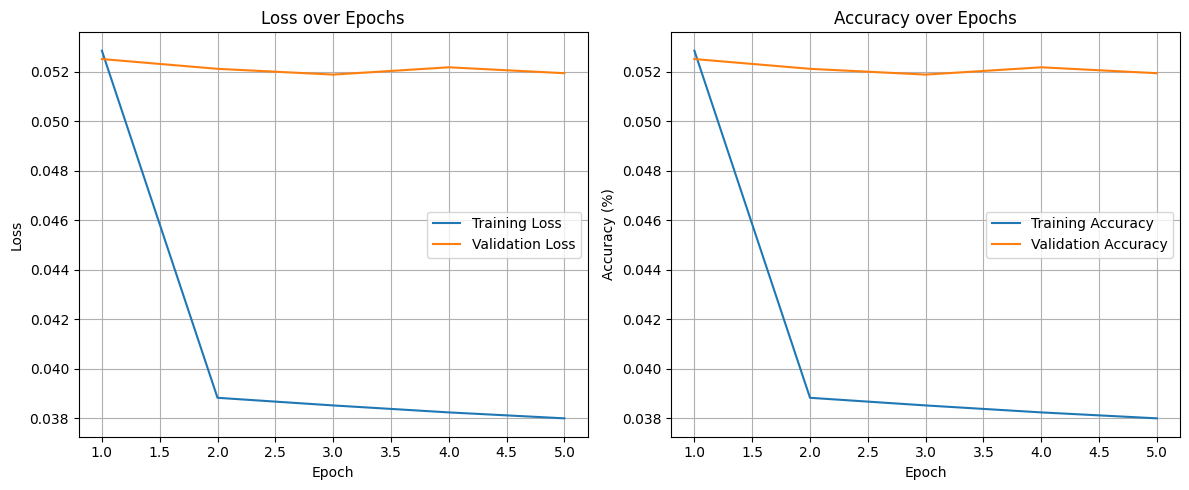

Test MSE:  0.0020
Test RMSE: 0.0447
Test R2:  0.6655


In [47]:
temperature_features = ['pressure','humidity','wind_speed','gust','visibility','solar_radiation','rainfall_7d_avg','is_monsoon','is_coastal']
temperature_labels = 'temperature'

temperature_linear_param_grid = {
    'epochs'         : [2],
    'batch_size'     : [128],
    'lr'             : [0.001],
}

# temperature_binary_param_grid = {
#     'epochs'         : [10, 20],
#     'batch_size'     : [32],
#     'lr'             : [0.001, 0.01],
# }

temperature_linear_model_gridsearch(temperature_features, temperature_labels, param_grid=temperature_linear_param_grid)

rainfall_features = ['pressure','humidity','wind_speed','gust','visibility','solar_radiation','rainfall_7d_avg','is_monsoon','is_coastal']
rainfall_binary_param_grid = {
    'epochs'         : [5],
    'batch_size'     : [128],
    'lr'             : [0.001],
}

# temperature_binary_param_grid = {
#     'epochs'         : [10, 20],
#     'batch_size'     : [32],
#     'lr'             : [0.001, 0.01],
# }

rainfall_binary_model_gridsearch(param_grid=rainfall_binary_param_grid)

rainfall_lstm_features = ['pressure','humidity','wind_speed','gust','visibility','solar_radiation','rainfall_7d_avg','is_monsoon','is_coastal']
rainfall_lstm_param_grid = {
    'epochs'         : [5],
    'batch_size'     : [128],
    'lr'             : [0.001],
    'sequence_length': [7],
    'hidden_size'    : [64],
    'num_layers'     : [2],
    'dropout'        : [0.1]
}

# rainfall_lstm_param_grid = {
#     'epochs'         : [10, 20],
#     'batch_size'     : [32],
#     'lr'             : [0.001, 0.01],
#     'sequence_length': [7, 14],
#     'hidden_size'    : [32, 64],
#     'num_layers'     : [1, 2],
#     'dropout'        : [0.0, 0.2]
# }

rainfall_lstm_model_gridsearch(param_grid=rainfall_lstm_param_grid)